# Tier C: coverage audit

**Is there enough news, for every sector ETF, in every period, to build a daily news signal?**

| Part | Output (in `My Drive/fnspid_news/results/`) |
|---|---|
| 1. Mapping rate, overall and per year, against the 60% threshold| `coverage_mapping_rate.csv`, `coverage_mapping_by_year.csv` |
| 1b. Mapping rate with the planned fallback (all US companies, Russell 3000) | `coverage_mapping_rate_fallback.csv`, `coverage_mapping_by_year_fallback.csv` |
| 2. Headlines per sector ETF per year, with heatmap | `coverage_sector_year.csv`, `coverage_sector_year.png` |
| 3. Headlines per sector ETF per trading day: typical count and share of days with no news | `coverage_sector_day.csv` |
| 4. Every news trading date exists in the ETF price table| `coverage_price_alignment.csv` |
| Mapped table for the next steps (gold sample, Semester 2) | `My Drive/fnspid_news/data/fnspid_mapped.parquet` |

**Inputs:** `fnspid_news/data/fnspid_clean.parquet`, plus `etf_extraction/data/sp500_sectors.csv`, `etf_extraction/data/trading_calendar.csv` and `etf_extraction/data/etf_prices.csv` in My Drive.

Counts use the backtest window **30 May 2007 to 29 Dec 2023** and the 11 sector ETFs that get a news signal. Runtime: a few minutes.

## 1. Setup

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from google.colab import drive
drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive'
NEWS_FILE = DRIVE + '/fnspid_news/data/fnspid_clean.parquet'
SP500_FILE = DRIVE + '/etf_extraction/data/sp500_sectors.csv'
CAL_FILE = DRIVE + '/etf_extraction/data/trading_calendar.csv'
PRICES_FILE = DRIVE + '/etf_extraction/data/etf_prices.csv'
RESULTS = DRIVE + '/fnspid_news/results'
MAPPED_FILE = DRIVE + '/fnspid_news/data/fnspid_mapped.parquet'
for f in [NEWS_FILE, SP500_FILE, CAL_FILE, PRICES_FILE]:
    assert os.path.exists(f), 'Missing ' + f
os.makedirs(RESULTS, exist_ok=True)

START, END = pd.Timestamp('2007-05-30'), pd.Timestamp('2023-12-29')     # backtest window
SECTOR_ETFS = ['XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB', 'VNQ', 'VOX']

news = pd.read_parquet(NEWS_FILE)
sp500 = pd.read_csv(SP500_FILE)
cal = pd.read_csv(CAL_FILE, index_col=0)
cal.index = pd.to_datetime(cal.index)
cal['close_utc'] = pd.to_datetime(cal['close_ny'], utc=True)
assert len(sp500) >= 400, 'sp500_sectors.csv has too few companies: re-run section 10 of Tier_C_ETF_Extraction'
print(f'{len(news):,} clean headlines | {len(sp500)} S&P 500 companies | {len(cal):,} trading days')

Mounted at /content/drive
5,541,739 clean headlines | 504 S&P 500 companies | 6,562 trading days


## 2. Link each headline to its sector ETF and its trading day

**ETF:** ticker → S&P 500 company → GICS sector → ETF. FNSPID uses the ticker at the time, so old tickers are renamed first (FB → META, BRK → BRK.B).

**Trading day:** the same rule as `to_trading_day()` in Tier_C_ETF_Extraction, written for millions of rows at once: before that day's close (New York time) → that day; after the close, weekend or holiday → next trading day; no time of day (`00:00:00 UTC`) → next trading day after the date. The six test cases from the ETF notebook are re-checked below.

In [2]:
TICKER_RENAMES = {'FB': 'META', 'BRK': 'BRK.B'}
news['ticker'] = news['Stock_symbol'].str.upper().str.replace(r'[- ]', '.', regex=True).replace(TICKER_RENAMES)
news = news.merge(sp500[['ticker', 'company', 'gics_sector', 'sector_etf']], on='ticker', how='left')

def trading_dates(published):
    """FNSPID UTC strings -> trading day (vectorised version of to_trading_day)."""
    ts = pd.to_datetime(pd.Series(published).str.replace(' UTC', '', regex=False),
                        format='%Y-%m-%d %H:%M:%S', errors='coerce', utc=True)
    utc = ts.dt.tz_convert(None)
    date_only = (utc.dt.hour == 0) & (utc.dt.minute == 0) & (utc.dt.second == 0)
    ny_day = ts.dt.tz_convert('America/New_York').dt.tz_localize(None).dt.normalize()
    ref_day = ny_day.where(~date_only, utc.dt.normalize()).to_numpy(dtype='datetime64[ns]')

    days = cal.index.to_numpy(dtype='datetime64[ns]')
    closes = cal['close_utc'].dt.tz_convert(None).to_numpy(dtype='datetime64[ns]')
    n = len(days)
    pos = np.searchsorted(days, ref_day, side='left')              # first trading day >= ref_day
    pc = np.clip(pos, 0, n - 1)
    is_trading = (pos < n) & (days[pc] == ref_day)
    before_close = is_trading & ~date_only.to_numpy() & (utc.to_numpy(dtype='datetime64[ns]') < closes[pc])
    out = np.where(before_close, pos, np.where(is_trading, pos + 1, pos))
    ok = ts.notna().to_numpy() & (out < n) & (ref_day >= days[0])
    return pd.to_datetime(np.where(ok, days[np.clip(out, 0, n - 1)], np.datetime64('NaT', 'ns')))

# Re-check the six hand-picked cases from the ETF notebook
tests = {'2020-03-10 15:00:00 UTC': '2020-03-10', '2020-03-10 21:30:00 UTC': '2020-03-11',
         '2021-01-08 22:00:00 UTC': '2021-01-11', '2019-12-25 15:00:00 UTC': '2019-12-26',
         '2019-11-29 19:00:00 UTC': '2019-12-02', '2020-05-22 00:00:00 UTC': '2020-05-26'}
got = trading_dates(list(tests)).strftime('%Y-%m-%d').tolist()
assert got == list(tests.values()), got
print('Trading-day rule: all 6 test cases pass')

news['trading_date'] = trading_dates(news['Date'])
news['in_window'] = news['trading_date'].between(START, END)
news['mapped'] = news['sector_etf'].isin(SECTOR_ETFS)
print(f"Headlines with a trading date in the window: {news['in_window'].sum():,}")

Trading-day rule: all 6 test cases pass
Headlines with a trading date in the window: 5,541,654


## 3. Mapping rate

Share of headlines that link to one of the 11 sector ETFs. The rule: **below 60% → fall back to sector-level aggregation and narrow the ETF universe.**

In [3]:
win = news[news['in_window']]
rates = pd.DataFrame({
    'headlines': [len(news), len(win)],
    'mapped_to_sector_etf': [int(news['mapped'].sum()), int(win['mapped'].sum())],
}, index=['all clean headlines', 'backtest window 2007-2023'])
rates['mapping_rate_pct'] = (rates['mapped_to_sector_etf'] / rates['headlines'] * 100).round(1)
rates.to_csv(RESULTS + '/coverage_mapping_rate.csv')

by_year = win.groupby(win['trading_date'].dt.year)['mapped'].agg(headlines='size', mapped='sum')
by_year['mapping_rate_pct'] = (by_year['mapped'] / by_year['headlines'] * 100).round(1)
by_year.index.name = 'year'
by_year.to_csv(RESULTS + '/coverage_mapping_by_year.csv')

rate = rates.loc['backtest window 2007-2023', 'mapping_rate_pct']
print(rates.to_string())
print(f"\nMapping rate {rate}% -> {'ABOVE' if rate >= 60 else 'BELOW'} the 60% threshold: "
      f"{'the fallback is NOT needed' if rate >= 60 else 'the fallback applies'}")
by_year

                           headlines  mapped_to_sector_etf  mapping_rate_pct
all clean headlines          5541739               1322019              23.9
backtest window 2007-2023    5541654               1321935              23.9

Mapping rate 23.9% -> BELOW the 60% threshold: the fallback applies


,headlines,mapped,mapping_rate_pct
year,,,
2009,12072,3152,26.1
2010,98444,24245,24.6
2011,185441,42650,23.0
2012,248879,57006,22.9
2013,256073,56378,22.0
2014,309668,65744,21.2
2015,494715,93339,18.9
2016,502392,110593,22.0
2017,435820,116890,26.8


## 3b. Planned fallback: sector-level aggregation with all US companies

The planning report's fallback for a mapping rate below 60% is **sector-level news aggregation**. Here every headline about a **US company in the Russell 3000** (about 2,600 stocks, iShares IWV holdings, same file format as IVV) is mapped through its GICS sector to the same 11 sector ETFs. S&P 500 companies keep their mapping; other US companies are added through their sector. Headlines about funds, preferred shares, warrants and non-US companies stay unmapped.

Both rates are reported, so the report can show the effect of the fallback. Sections 4 to 7 below still use the main S&P 500 mapping.

In [4]:
import io, requests
IWV_URL = 'https://www.ishares.com/us/products/239714/ishares-russell-3000-etf/latest-holdings.csv'
IWV_FILE = DRIVE + '/etf_extraction/data/iwv_holdings.csv'
if not os.path.exists(IWV_FILE):
    r = requests.get(IWV_URL, headers={'User-Agent': 'Mozilla/5.0'}, timeout=60)
    r.raise_for_status()
    open(IWV_FILE, 'wb').write(r.content)

text = open(IWV_FILE, encoding='utf-8-sig').read()
lines = text.splitlines()
iwv_date = re.search(r'"(.+)"', next(l for l in lines if l.startswith('Fund Holdings as of'))).group(1)
header = next(i for i, l in enumerate(lines) if l.startswith('Ticker,'))
iwv = pd.read_csv(io.StringIO(text), skiprows=header, on_bad_lines='skip')
iwv = iwv[iwv['Asset Class'] == 'Equity']
us = pd.DataFrame({'ticker': iwv['Ticker'].astype(str).str.strip().replace({'BRKB': 'BRK.B', 'BFB': 'BF.B'})
                             .str.upper().str.replace(r'[- ]', '.', regex=True),
                   'gics_sector': iwv['Sector'].replace({'Communication': 'Communication Services'})})
sector_to_etf = sp500.drop_duplicates('gics_sector').set_index('gics_sector')['sector_etf']
us['sector_etf_us'] = us['gics_sector'].map(sector_to_etf)
us = us.dropna(subset=['sector_etf_us']).drop_duplicates('ticker')
print(f'Russell 3000 holdings as of {iwv_date}: {len(us):,} US companies with a sector')

news = news.merge(us[['ticker', 'sector_etf_us']], on='ticker', how='left')
news['sector_etf_broad'] = news['sector_etf'].fillna(news['sector_etf_us'])
news['mapped_broad'] = news['sector_etf_broad'].isin(SECTOR_ETFS)

win = news[news['in_window']]
both = pd.DataFrame({
    'headlines': [len(win), len(win)],
    'mapped': [int(win['mapped'].sum()), int(win['mapped_broad'].sum())],
}, index=['main: S&P 500 companies', 'fallback: all US companies (Russell 3000)'])
both['mapping_rate_pct'] = (both['mapped'] / both['headlines'] * 100).round(1)
both.to_csv(RESULTS + '/coverage_mapping_rate_fallback.csv')

by_year_broad = win.groupby(win['trading_date'].dt.year)[['mapped', 'mapped_broad']].mean().mul(100).round(1)
by_year_broad.columns = ['main_rate_pct', 'fallback_rate_pct']
by_year_broad.index.name = 'year'
by_year_broad.to_csv(RESULTS + '/coverage_mapping_by_year_fallback.csv')

rate_b = both['mapping_rate_pct'].iloc[1]
print(both.to_string())
print(f"\nWith the fallback: {rate_b}% -> {'ABOVE' if rate_b >= 60 else 'BELOW'} the 60% threshold")
by_year_broad

Russell 3000 holdings as of Oct 21, 2026: 2,587 US companies with a sector
                                           headlines   mapped  mapping_rate_pct
main: S&P 500 companies                      5541654  1321935              23.9
fallback: all US companies (Russell 3000)    5541654  2435520              43.9

With the fallback: 43.9% -> BELOW the 60% threshold


,main_rate_pct,fallback_rate_pct
year,,
2009,26.1,43.3
2010,24.6,42.9
2011,23.0,42.2
2012,22.9,43.3
2013,22.0,43.2
2014,21.2,42.0
2015,18.9,38.2
2016,22.0,42.4
2017,26.8,48.7


## 4. Relevance: headlines about one named company

Same rule as the pilot sample: the headline names the company it is tagged to and is not a template or a multi-company list. It is counted here so the report can say how much of the mapped news is informative; Semester 2 can use either version.

In [5]:
import re

# A headline is kept only if it is really about ONE named company:
#   (1) it names the company it is tagged to (company name or its ticker), and
#   (2) it is not a template or a multi-company list.
TEMPLATES = (r'\bBuys\b.*,|\bSells\b.*,|Movers|Sector Update|Lightning Round|Option Alert|Options? Activity|'
             r'Dividend Report|Ex-Dividend Date|Stocks? (You|To|That|Hitting)|\d+ (AI )?Stocks?\b|Markets Now|'
             r'Put And Call|Pre-?market|After-?Hours|Midday|Mid-Day|Biggest Movers|52-Week')
GENERIC = {'THE', 'FIRST', 'GENERAL', 'AMERICAN', 'UNITED', 'INTERNATIONAL', 'NATIONAL', 'PUBLIC', 'DIGITAL',
           'SOUTHERN', 'WESTERN', 'NORTHERN', 'CAPITAL', 'HEALTH', 'UNIVERSAL', 'GLOBAL', 'ROYAL', 'CHARLES', 'HOST'}

def simple(text):                                                    # lower case, punctuation -> spaces
    return ' ' + re.sub(r'[^a-z0-9&]+', ' ', str(text).lower().replace('.com', '')).strip() + ' '

def name_key(company):
    words = simple(company).split()
    if not words:
        return ''
    if (words[0].upper() in GENERIC or len(words[0]) < 3) and len(words) > 1:
        return words[0] + ' ' + words[1]                             # e.g. 'general motors', 't mobile'
    return words[0]

def is_relevant(title, company, ticker):
    if re.search(TEMPLATES, title, flags=re.IGNORECASE):
        return False
    caps = re.findall(r'\b[A-Z]{1,5}\b', title)
    if title.count(',') >= 2 and len(caps) >= 3:                     # e.g. "HDV, DUK, D, UPS: ..."
        return False
    key = name_key(company)
    names_company = bool(key) and f' {key} ' in simple(title)
    names_ticker = len(ticker) >= 2 and re.search(rf'\b{re.escape(ticker)}\b', title) is not None
    return names_company or names_ticker

m = news[news['in_window'] & news['mapped']].copy()
m['relevant'] = [is_relevant(t, c, k) for t, c, k in zip(m['Article_title'], m['company'], m['ticker'])]
print(f"Mapped headlines in the window: {len(m):,} | about one named company: {m['relevant'].mean():.1%}")

Mapped headlines in the window: 1,321,935 | about one named company: 34.9%


## 5. Headlines per sector ETF per year

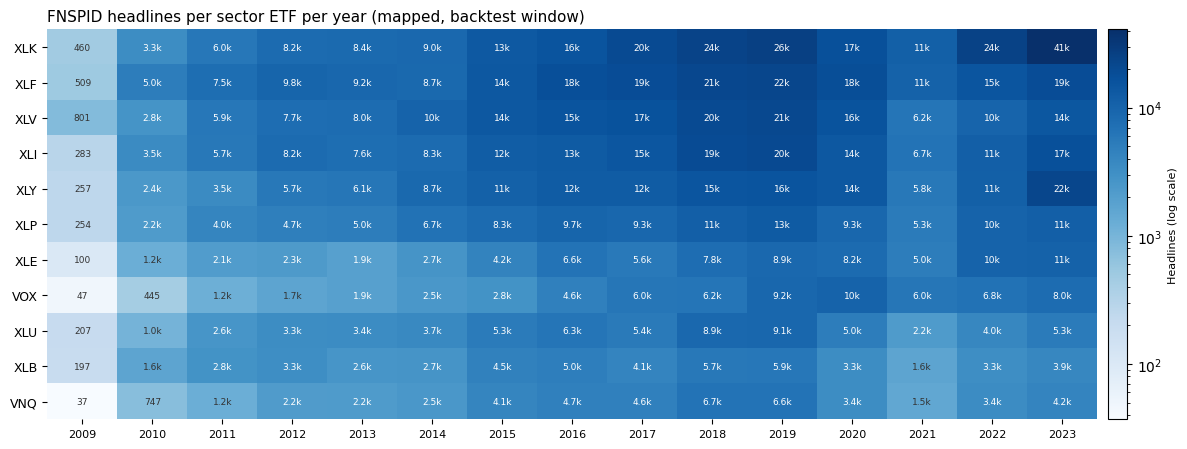

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,total
sector_etf,,,,,,,,,,,,,,,,
XLK,460,3297,6008,8196,8444,9040,13377,15633,19667,24160,25760,17181,11108,24466,40866,227663
XLF,509,4971,7524,9823,9222,8651,14036,17737,18684,21291,22288,18449,10518,15120,18740,197563
XLV,801,2754,5915,7717,8023,10308,13921,15300,16539,19795,21176,16105,6202,10037,14141,168734
XLI,283,3534,5728,8160,7582,8335,11946,12809,14582,19295,20301,14023,6669,11379,17367,161993
XLY,257,2435,3504,5728,6082,8714,10844,12310,12285,15202,15541,13764,5756,11241,22308,145971
XLP,254,2197,4044,4737,4984,6718,8302,9703,9320,11444,12601,9312,5295,10339,11383,110633
XLE,100,1203,2122,2252,1895,2658,4244,6568,5602,7785,8914,8199,5040,10268,10571,77421
VOX,47,445,1193,1658,1888,2450,2826,4580,6048,6213,9188,10277,6030,6816,8040,67699
XLU,207,1024,2593,3311,3435,3726,5269,6294,5432,8892,9083,4976,2210,3980,5310,65742


In [6]:
m['year'] = m['trading_date'].dt.year
sector_year = m.pivot_table(index='sector_etf', columns='year', values='Article_title', aggfunc='size', fill_value=0)
sector_year = sector_year.reindex(SECTOR_ETFS).fillna(0).astype(int)
sector_year['total'] = sector_year.sum(axis=1)
sector_year = sector_year.sort_values('total', ascending=False)
sector_year.to_csv(RESULTS + '/coverage_sector_year.csv')

# Heatmap: one blue scale, darker = more headlines, log scale because counts range widely
grid = sector_year.drop(columns='total')
fig, ax = plt.subplots(figsize=(12, 4.6))
norm = LogNorm(vmin=max(grid.values.min(), 1), vmax=grid.values.max())
im = ax.imshow(grid.clip(lower=1), cmap='Blues', norm=norm, aspect='auto')
ax.set_xticks(range(grid.shape[1]), grid.columns, fontsize=8)
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=9)
for (r, c), v in np.ndenumerate(grid.values):
    label = f'{v / 1000:.0f}k' if v >= 10000 else f'{v / 1000:.1f}k' if v >= 1000 else str(v)
    ax.text(c, r, label, ha='center', va='center', fontsize=6.5,
            color='white' if norm(max(v, 1)) > 0.55 else '#333333')        # white text on dark cells
ax.set_title('FNSPID headlines per sector ETF per year (mapped, backtest window)', fontsize=11, loc='left')
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label('Headlines (log scale)', fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS + '/coverage_sector_year.png', dpi=150)
plt.show()
sector_year

## 6. Headlines per sector ETF per trading day

The news signal is daily, so the key question is how often a sector has **no news at all** on a trading day. Every trading day in the window counts, including days with zero headlines. Reported for the whole window and for the two periods with different news density (2007–2015 dense, 2016–2023 thinner).

In [7]:
days = cal.index[(cal.index >= START) & (cal.index <= END)]
periods = {'2007-2023': (START, END), '2007-2015': (START, pd.Timestamp('2015-12-31')),
           '2016-2023': (pd.Timestamp('2016-01-01'), END)}

def day_stats(df, label):
    counts = df.groupby(['sector_etf', 'trading_date']).size()
    rows = []
    for etf in SECTOR_ETFS:
        per_day = counts.get(etf, pd.Series(dtype=int)).reindex(days, fill_value=0)
        for p, (a, b) in periods.items():
            s = per_day[(per_day.index >= a) & (per_day.index <= b)]
            rows.append({'sector_etf': etf, 'headlines': label, 'period': p, 'trading_days': len(s),
                         'median_per_day': float(s.median()), 'mean_per_day': round(s.mean(), 1),
                         'pct_days_no_news': round((s == 0).mean() * 100, 1),
                         'pct_days_under_3': round((s < 3).mean() * 100, 1)})
    return pd.DataFrame(rows)

sector_day = pd.concat([day_stats(m, 'all mapped'), day_stats(m[m['relevant']], 'about one named company')])
sector_day.to_csv(RESULTS + '/coverage_sector_day.csv', index=False)

view = sector_day[sector_day['headlines'] == 'all mapped'].pivot(index='sector_etf', columns='period',
                                                                  values=['median_per_day', 'pct_days_no_news'])
view.reindex(SECTOR_ETFS)

median_per_day                     pct_days_no_news            \
period          2007-2015 2007-2023 2016-2023        2007-2015 2007-2023   
sector_etf                                                                 
XLK                  21.0      43.0      81.0             26.5      13.7   
XLF                  24.0      42.0      65.0             26.2      13.8   
XLE                   5.0      14.0      29.0             29.1      15.3   
XLV                  20.0      35.0      54.0             26.1      13.7   
XLI                  19.0      33.0      53.0             26.4      13.9   
XLY                  13.0      30.0      48.0             26.8      14.1   
XLP                  12.0      24.0      37.0             26.9      14.1   
XLU                   7.0      12.0      19.0             29.0      15.3   
XLB                   7.0      11.0      15.0             26.7      14.2   
VNQ                   4.0       9.0      15.0             31.6      16.7   
VOX                   3.0      12.0      25.0             33.6      17.6   

                      
period     2016-2023  
sector_etf            
XLK              0.0  
XLF              0.4  
XLE              0.4  
XLV              0.4  
XLI              0.4  
XLY              0.4  
XLP              0.4  
XLU              0.4  
XLB              0.7  
VNQ              0.7  
VOX              0.4

## 6b. Every news trading date exists in the price table

Each headline's trading date must be a day with ETF prices, otherwise its news cannot be matched to a return. Expected result: **0 missing days**.

In [8]:
prices = pd.read_csv(PRICES_FILE, index_col='date', parse_dates=True)
price_days = set(prices.index[prices['SPY'].notna()])
news_days = set(m['trading_date'].dropna().unique())
missing = sorted(d for d in news_days if d not in price_days)

alignment = pd.DataFrame({'check': ['news trading days in window', 'price days', 'news trading days without a price'],
                          'count': [len(news_days), len(price_days), len(missing)]})
alignment.to_csv(RESULTS + '/coverage_price_alignment.csv', index=False)
print(alignment.to_string(index=False))
print('First missing days:', [str(pd.Timestamp(d).date()) for d in missing[:10]] if missing else 'none')
print('Every news trading date has a price' if not missing else 'CHECK the missing days above')

                            check  count
      news trading days in window   3639
                       price days   6541
news trading days without a price      0
First missing days: none
Every news trading date has a price


## 6c. News for every ETF, including bonds, gold, commodities and cash

Sections 5–6 count only **company news** mapped to the 11 sector ETFs. FNSPID also has headlines tagged with an **ETF's own ticker** (e.g. "GLD sees record inflows", "TLT falls as yields rise"). This section counts both kinds for **all 21 ETFs** in `etf_universe.csv`:

- `own_ticker_headlines`: headlines tagged with the ETF's own ticker
- `company_headlines`: company headlines mapped through the S&P 500 sector (sector ETFs only)
- `pct_days_with_news`: share of trading days with at least one headline of either kind

**Decision rule (fixed before looking at the results):** an ETF can get a news signal if it has news on **at least 50% of trading days in 2016–2023**. Otherwise it keeps historical volatility only.

The ETF-ticker headlines are saved to `fnspid_news/data/fnspid_etf_own_news.parquet` so they can be used in the signal later.

In [9]:
universe = pd.read_csv(DRIVE + '/etf_extraction/data/etf_universe.csv')
assert {'GLD', 'TLT', 'AGG', 'XLK'} <= set(universe['ticker']), 'etf_universe.csv not found or incomplete: check etf_extraction/data'
ETFS = universe['ticker'].tolist()
MIN_PCT_DAYS = 50                                                    # decision rule, see above

# (a) headlines tagged with an ETF's own ticker, in the backtest window
own = news[news['ticker'].isin(ETFS) & news['in_window']]
own[['Date', 'trading_date', 'Article_title', 'Stock_symbol', 'ticker']].to_parquet(
    DRIVE + '/fnspid_news/data/fnspid_etf_own_news.parquet', index=False)

# (b) company headlines mapped to a sector ETF = m (section 4)
rows = []
for period, a in {'2010-2023': pd.Timestamp('2010-01-01'), '2016-2023': pd.Timestamp('2016-01-01')}.items():
    days = cal.index[(cal.index >= a) & (cal.index <= END)]
    for e in universe.itertuples():
        own_days = own.loc[(own['ticker'] == e.ticker) & (own['trading_date'] >= a), 'trading_date']
        comp_days = m.loc[(m['sector_etf'] == e.ticker) & (m['trading_date'] >= a), 'trading_date']
        all_days = pd.concat([own_days, comp_days])
        rows.append({'period': period, 'etf': e.ticker, 'group': e.group, 'role': e.role,
                     'own_ticker_headlines': len(own_days), 'company_headlines': len(comp_days),
                     'headlines_per_day': round(len(all_days) / len(days), 2),
                     'pct_days_with_news': round(all_days.nunique() / len(days) * 100, 1)})

etf_news = pd.DataFrame(rows)
etf_news['signal_possible'] = etf_news['pct_days_with_news'] >= MIN_PCT_DAYS
etf_news.to_csv(RESULTS + '/coverage_all_etf_news.csv', index=False)

check = etf_news[etf_news['period'] == '2016-2023'].set_index('etf')
in_uni = check[check['role'] == 'Universe']
print(f"Universe ETFs with news on >= {MIN_PCT_DAYS}% of days (2016-2023):", in_uni.index[in_uni['signal_possible']].tolist())
print('Universe ETFs below the rule (historical volatility only):', in_uni.index[~in_uni['signal_possible']].tolist())
check.drop(columns='period')

Universe ETFs with news on >= 50% of days (2016-2023): ['XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB', 'VNQ', 'VOX', 'AGG', 'GLD']
Universe ETFs below the rule (historical volatility only): ['IEF', 'TLT', 'LQD', 'DBC', 'BIL']


,group,role,own_ticker_headlines,company_headlines,headlines_per_day,pct_days_with_news,signal_possible
etf,,,,,,,
XLK,Equity sector,Universe,4589,178841,91.17,100.0,True
XLF,Equity sector,Universe,4614,142827,73.28,99.6,True
XLE,Equity sector,Universe,4912,62947,33.73,99.6,True
XLV,Equity sector,Universe,1711,119295,60.14,99.6,True
XLI,Equity sector,Universe,1243,116425,58.48,99.6,True
XLY,Equity sector,Universe,3235,108407,55.49,99.6,True
XLP,Equity sector,Universe,3018,79397,40.96,99.6,True
XLU,Equity sector,Universe,3639,46177,24.76,99.6,True
XLB,Equity sector,Universe,1695,32882,17.19,99.3,True


## 7. Save the mapped table for the next steps

In [10]:
keep = ['Date', 'trading_date', 'Article_title', 'Stock_symbol', 'ticker', 'company', 'gics_sector', 'sector_etf', 'relevant']
m[keep].to_parquet(MAPPED_FILE, index=False)
print('Saved', MAPPED_FILE, f'| {len(m):,} rows')
print('Results in', RESULTS, ':', sorted(f for f in os.listdir(RESULTS) if f.startswith('coverage')))

Saved /content/drive/MyDrive/fnspid_news/data/fnspid_mapped.parquet | 1,321,935 rows
Results in /content/drive/MyDrive/fnspid_news/results : ['coverage_all_etf_news.csv', 'coverage_cross_asset_own_news.csv', 'coverage_mapping_by_year.csv', 'coverage_mapping_by_year_fallback.csv', 'coverage_mapping_rate.csv', 'coverage_mapping_rate_fallback.csv', 'coverage_price_alignment.csv', 'coverage_sector_day.csv', 'coverage_sector_year.csv', 'coverage_sector_year.png']


In [11]:
# Contingency decision: which universe ETFs keep a news signal
final = check[check['role'] == 'Universe'][['group', 'own_ticker_headlines', 'company_headlines', 'pct_days_with_news', 'signal_possible']].copy()
final['news_signal'] = final['signal_possible'].map({True: 'Yes (from 2010)', False: 'No - historical volatility only'})
final = final.drop(columns='signal_possible')
final

,group,own_ticker_headlines,company_headlines,pct_days_with_news,news_signal
etf,,,,,
XLK,Equity sector,4589,178841,100.0,Yes (from 2010)
XLF,Equity sector,4614,142827,99.6,Yes (from 2010)
XLE,Equity sector,4912,62947,99.6,Yes (from 2010)
XLV,Equity sector,1711,119295,99.6,Yes (from 2010)
XLI,Equity sector,1243,116425,99.6,Yes (from 2010)
XLY,Equity sector,3235,108407,99.6,Yes (from 2010)
XLP,Equity sector,3018,79397,99.6,Yes (from 2010)
XLU,Equity sector,3639,46177,99.6,Yes (from 2010)
XLB,Equity sector,1695,32882,99.3,Yes (from 2010)
